# Session 7 lab (draft): Trends, returns and a decision dashboard

<p class="lead">
Add time to your segment comparison, read growth figures without being fooled by the seasons, use the returns list carefully, and bring it all together in one dashboard with a recommendation.
</p>

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Aayush181509/AnalyticsLecture/blob/main/notebooks/07_trends_and_growth_lab.ipynb)

Open this notebook in Google Colab with the button above, then run each cell from top to bottom with **Shift + Enter**. Save your own copy with **File → Save a copy in Drive**.

---

## The business decision

The commercial lead asks:

> *"Before we test any change, show me how sales have moved over time, whether returns differ between segments, and which one test you would run first."*

A single snapshot cannot answer this. A month can look like a crash or a boom simply because of the time of year.

---

## What you will be able to do

By the end of this lesson you will be able to:

1. Build a monthly Sales trend and recognise seasonal patterns.
2. Calculate month-on-month and year-on-year growth, and explain when each is fair.
3. Explain why a blank growth value means "no comparison", and why filtering too early creates blanks.
4. Measure the share of orders on the returns list, and state what it cannot tell you.
5. Combine three charts into one dashboard and write a recommendation for a test.

**Evidence you keep:** your dashboard, your growth and returns definitions, and a five-sentence recommendation. Together they are your **retail portfolio checkpoint**.

---

## Before you start

- Complete the [Session 5 lab](05_metrics_and_kpis_lab.md), where you built the segment KPI table.
- Re-read [cherry-picked time windows](../foundations/misleading-statistics.md) and [storytelling with data](../foundations/storytelling.md).

> **About the data**
>
> Superstore is a **fictitious** sample. Sales are in the file's own **source monetary units**; the currency is not stated. Patterns in this lesson describe the sample, and a pattern over time shows *when* something happened, not *why*.

Run the setup cell, then load the table.

In [1]:
# Course data setup. Run this cell first; you do not need to understand it yet.
# It downloads the Superstore sample from Tableau's website, checks it is the
# exact version this course was written for, and prepares the order-lines table.
import hashlib
import os
import urllib.request

import matplotlib.pyplot as plt
import pandas as pd

SOURCE_URL = "https://public.tableau.com/app/sample-data/sample_-_superstore.xls"
EXPECTED_SHA256 = "5045ed4fec49cae2cc0dfc5ab0d204ba09efa767fe00c996822499e8cc42fbbd"
SOURCE_FILE = os.environ.get("COURSE_XLS_PATH", "sample_-_superstore.xls")

try:
    import xlrd  # noqa: F401  (needed to read .xls files)
except ImportError:
    import subprocess
    import sys

    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "xlrd"])

if not os.path.exists(SOURCE_FILE):
    urllib.request.urlretrieve(SOURCE_URL, SOURCE_FILE)

with open(SOURCE_FILE, "rb") as f:
    digest = hashlib.sha256(f.read()).hexdigest()
if digest != EXPECTED_SHA256:
    print("WARNING: Tableau has changed this sample file since the course was written.")
    print("Your numbers will differ from the lesson. Ask your facilitator for the course copy.")


def load_orders():
    """Return one row per order line, orders placed 2023-01-01 to 2025-12-31."""
    raw = pd.read_excel(SOURCE_FILE, sheet_name="Orders")
    returns = pd.read_excel(SOURCE_FILE, sheet_name="Returns")

    # Orders with more than one Customer ID (a known data issue), found before filtering.
    ids_per_order = raw.groupby("Order ID")["Customer ID"].nunique()
    conflict_orders = set(ids_per_order[ids_per_order > 1].index)

    in_scope = (raw["Order Date"] >= "2023-01-01") & (raw["Order Date"] < "2026-01-01")
    df = raw.loc[in_scope].copy()

    df = df.rename(columns={
        "Row ID": "row_id", "Order ID": "order_id", "Order Date": "order_date",
        "Ship Date": "ship_date", "Ship Mode": "ship_mode", "Customer ID": "customer_id",
        "Segment": "segment", "Country/Region": "country_region", "Region": "region",
        "Category": "category", "Sub-Category": "sub_category", "Product ID": "product_id",
        "Product Name": "product_name", "Sales": "sales", "Quantity": "quantity",
        "Discount": "discount", "Profit": "profit",
    })
    df["returned_order_flag"] = df["order_id"].isin(set(returns["Order ID"])).astype(int)
    df["customer_order_conflict"] = df["order_id"].isin(conflict_orders).astype(int)
    df["customer_analysis_eligible"] = 1 - df["customer_order_conflict"]
    df["order_to_ship_days"] = (df["ship_date"] - df["order_date"]).dt.days
    df["order_month"] = df["order_date"].dt.to_period("M").dt.to_timestamp()

    columns = [
        "row_id", "order_id", "order_date", "ship_date", "ship_mode", "customer_id",
        "segment", "country_region", "region", "category", "sub_category", "product_id",
        "product_name", "sales", "quantity", "discount", "profit", "returned_order_flag",
        "customer_analysis_eligible", "customer_order_conflict", "order_to_ship_days",
        "order_month",
    ]
    return df[columns].sort_values("row_id").reset_index(drop=True)


pd.set_option("display.float_format", "{:,.2f}".format)
plt.rcParams.update({
    "figure.figsize": (8, 4),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": "#e6e5e1",
    "axes.prop_cycle": plt.cycler(color=["#2a78d6", "#eb6834", "#1baf7a"]),
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
})
print("Setup complete.")

Setup complete.


In [2]:
df = load_orders()
print("Rows (order lines):", len(df))
print("Different orders:  ", df["order_id"].nunique())

Rows (order lines):

 6815
Different orders:   3388


---

## Part 1: The monthly trend

Every row has an `order_month` column: the **first day** of the month the order was placed. Grouping by it gives one Sales total per calendar month.

In [3]:
monthly = df.groupby("order_month")["sales"].sum()
monthly.head(6)

order_month
2023-01-01   14,518.06
2023-02-01    4,519.89
2023-03-01   56,933.91
2023-04-01   28,295.35
2023-05-01   26,319.77
2023-06-01   34,669.48
Name: sales, dtype: float64

### Check that no month is missing

Growth calculations compare a month with an earlier month. If a month were missing, the "previous" row would silently be the wrong month. So before anything else, build the full list of calendar months and compare.

`pd.date_range(..., freq="MS")` makes one date per **M**onth **S**tart.

In [4]:
all_months = pd.date_range("2023-01-01", "2025-12-01", freq="MS")
missing = all_months.difference(monthly.index)

print("Months expected:", len(all_months))
print("Months with Sales:", len(monthly))
print("Missing months:", len(missing))

Months expected: 36
Months with Sales: 36
Missing months: 0


Read the output above. If "Missing months" is 0, every calendar month is present and the series is **complete**. We still line the series up against `all_months` with `reindex`, so a gap would show as a blank rather than being skipped.

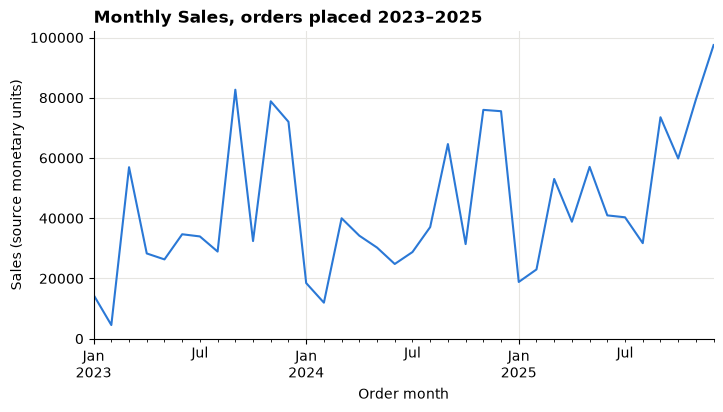

In [5]:
monthly = monthly.reindex(all_months)

monthly.plot(title="Monthly Sales, orders placed 2023–2025")
plt.xlabel("Order month")
plt.ylabel("Sales (source monetary units)")
plt.show()

### One line per segment

`unstack()` turns the segment level into columns, so each segment becomes its own line.

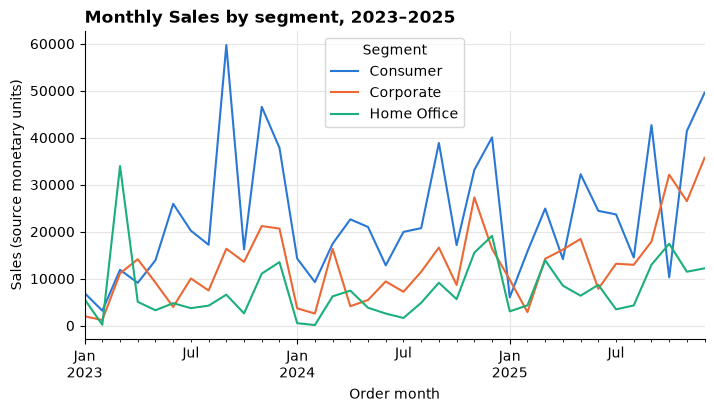

In [6]:
monthly_by_segment = df.groupby(["order_month", "segment"])["sales"].sum().unstack()

monthly_by_segment.plot(title="Monthly Sales by segment, 2023–2025")
plt.xlabel("Order month")
plt.ylabel("Sales (source monetary units)")
plt.legend(title="Segment")
plt.show()

### Is there a seasonal pattern?

Put the three years on top of each other: one line per year, with the month of the year along the bottom.

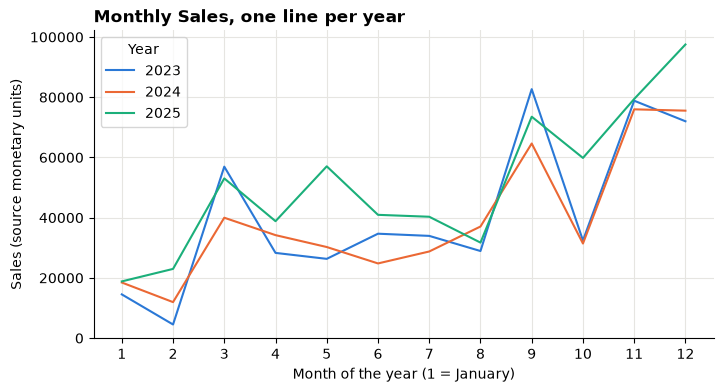

In [7]:
by_year = pd.DataFrame({
    "year": monthly.index.year,
    "month": monthly.index.month,
    "sales": monthly.values,
})
seasons = by_year.pivot(index="month", columns="year", values="sales")

seasons.plot(title="Monthly Sales, one line per year")
plt.xlabel("Month of the year (1 = January)")
plt.ylabel("Sales (source monetary units)")
plt.xticks(range(1, 13))
plt.legend(title="Year")
plt.show()

A quick text check: the three highest and two lowest months in each year.

In [8]:
for year, sales in monthly.groupby(monthly.index.year):
    highest = ", ".join(sales.nlargest(3).index.strftime("%b"))
    lowest = ", ".join(sales.nsmallest(2).index.strftime("%b"))
    print(year, "| highest:", highest, "| lowest:", lowest)

2023 | highest: Sep, Nov, Dec | lowest: Feb, Jan
2024 | highest: Nov, Dec, Sep | lowest: Feb, Jan
2025 | highest: Dec, Nov, Sep | lowest: Jan, Feb


> **What do you notice?**
>
> Write down three observations from the charts and the output above. Are the same months high every year? Are the same months low? Does the pattern look similar in every segment?

---

## Part 2: Two kinds of growth

| Growth type | Compares each month with | pandas |
|---|---|---|
| **Month-on-month (MoM)** | the previous calendar month | `pct_change()` |
| **Year-on-year (YoY)** | the same month one year earlier | `pct_change(periods=12)` |

Both use the same formula: *(this month − comparison month) ÷ comparison month*.

> **Only on a complete monthly series**
>
> `pct_change` compares each row with the row above it (or 12 rows above). That only means "previous month" or "same month last year" because we checked that all 36 months are present and in order.

To see what is being compared, the table below also keeps the comparison values. `shift(1)` moves each value down one row; `shift(12)` moves it down twelve rows.

In [9]:
growth = pd.DataFrame({"sales": monthly})
growth["previous_month"] = growth["sales"].shift(1)
growth["mom_growth"] = growth["sales"].pct_change()
growth["same_month_last_year"] = growth["sales"].shift(12)
growth["yoy_growth"] = growth["sales"].pct_change(periods=12)

# A comparison month with zero Sales gives no fair growth figure: treat it as blank.
growth["mom_growth"] = growth["mom_growth"].where(growth["previous_month"] != 0)
growth["yoy_growth"] = growth["yoy_growth"].where(growth["same_month_last_year"] != 0)

The full table has 36 rows. To keep it readable we show a few months and format growth as percentages. `as_pct` writes a blank growth value as the words "no comparison".

In [10]:
def as_pct(value):
    if pd.isna(value):
        return "no comparison"
    return f"{value:+.1%}"


def growth_table(table, months):
    rows = table.loc[months]
    return pd.DataFrame({
        "Sales": rows["sales"].map("{:,.0f}".format),
        "MoM growth": rows["mom_growth"].map(as_pct),
        "YoY growth": rows["yoy_growth"].map(as_pct),
    }, index=rows.index.strftime("%b %Y"))


growth_table(growth, ["2023-01-01", "2023-02-01", "2023-03-01",
                      "2024-01-01", "2025-01-01", "2025-12-01"])

,Sales,MoM growth,YoY growth
Jan 2023,"14,518",no comparison,no comparison
Feb 2023,"4,520",-68.9%,no comparison
Mar 2023,"56,934",+1159.6%,no comparison
Jan 2024,"18,462",-74.4%,+27.2%
Jan 2025,"18,830",-75.1%,+2.0%
Dec 2025,"97,502",+22.8%,+29.1%


Read the output above row by row:

1. **January 2023** is the first month in the file, so it has no previous month and no month a year earlier.
2. **Every 2023 month** has no year-earlier month in the file, so its YoY growth is blank.
3. Look at **March 2023**. A very large MoM figure often just means the previous month was small, not that something remarkable happened.
4. Compare **January 2025** MoM with January 2025 YoY. Do they tell the same story?

### Where are the blanks?

`isna()` marks blanks as `True`; summing counts them. Here we count blanks in each year.

In [11]:
growth[["mom_growth", "yoy_growth"]].isna().groupby(growth.index.year).sum()

,mom_growth,yoy_growth
2023,1,12
2024,0,0
2025,0,0


> **Blank is not zero**
>
> A blank (`NaN`) means **"no comparison available"**. It is not 0% growth, and you must never fill it with 0. A table or chart that shows 0% for January 2023 is wrong.

### See the difference on a chart

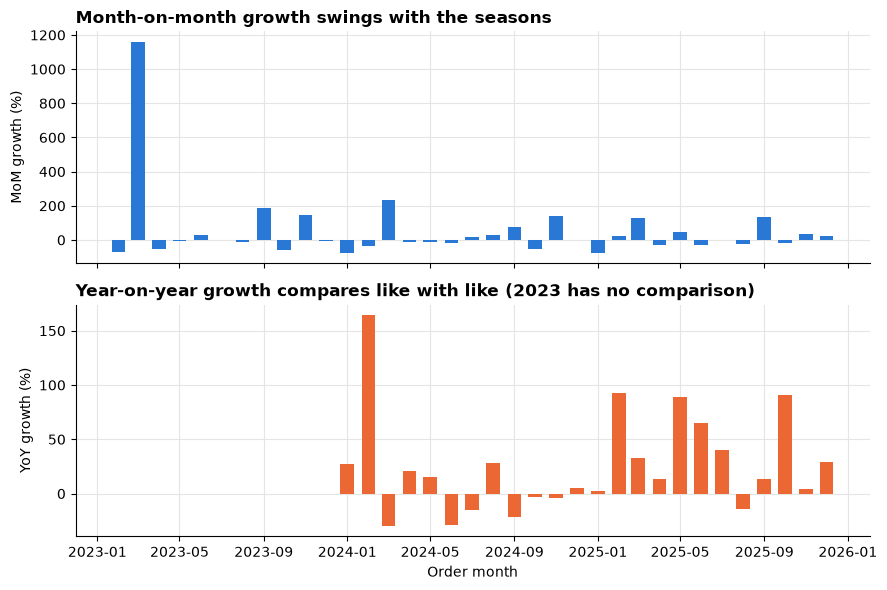

In [12]:
fig, (ax_mom, ax_yoy) = plt.subplots(2, 1, figsize=(9, 6), sharex=True)

ax_mom.bar(growth.index, growth["mom_growth"] * 100, width=20)
ax_mom.set_title("Month-on-month growth swings with the seasons")
ax_mom.set_ylabel("MoM growth (%)")

ax_yoy.bar(growth.index, growth["yoy_growth"] * 100, width=20, color="#eb6834")
ax_yoy.set_title("Year-on-year growth compares like with like (2023 has no comparison)")
ax_yoy.set_ylabel("YoY growth (%)")
ax_yoy.set_xlabel("Order month")

fig.tight_layout()
plt.show()

### Which one is fair?

| Growth type | Good for | Can mislead when |
|---|---|---|
| Month-on-month | Spotting sudden changes | The business is seasonal: January after a busy December always looks like a crash |
| Year-on-year | Comparing like with like across seasons | A one-off event happened in the same month last year |

---

## Part 3: Filtering can remove the comparison

Suppose you only care about 2025. There are two orders of work:

1. **Filter, then compute:** keep only 2025 rows, then calculate growth.
2. **Compute, then filter:** calculate growth on all 36 months, then show only 2025.

Run both and compare January and February 2025.

In [13]:
# 1. Filter first, then compute growth
only_2025 = df[df["order_date"].dt.year == 2025]
monthly_2025 = only_2025.groupby("order_month")["sales"].sum()
filter_first = pd.DataFrame({
    "mom_growth": monthly_2025.pct_change(),
    "yoy_growth": monthly_2025.pct_change(periods=12),
})

# 2. Compute growth on all months first, then keep 2025
compute_first = growth.loc["2025", ["mom_growth", "yoy_growth"]]

check_months = ["2025-01-01", "2025-02-01"]
pd.DataFrame({
    "MoM, filter first": filter_first.loc[check_months, "mom_growth"].map(as_pct),
    "MoM, compute first": compute_first.loc[check_months, "mom_growth"].map(as_pct),
    "YoY, filter first": filter_first.loc[check_months, "yoy_growth"].map(as_pct),
    "YoY, compute first": compute_first.loc[check_months, "yoy_growth"].map(as_pct),
}, index=pd.DatetimeIndex(check_months).strftime("%b %Y"))

,"MoM, filter first","MoM, compute first","YoY, filter first","YoY, compute first"
Jan 2025,no comparison,-75.1%,no comparison,+2.0%
Feb 2025,+22.0%,+22.0%,no comparison,+92.3%


In the output above, filtering first leaves January 2025 with no row above it, so its MoM growth becomes blank. And because the filtered series holds only 12 months, **every** YoY value becomes blank: December 2024 and all of 2024 were removed before the calculation could see them.

> **Rule**
>
> **Compute growth on the complete monthly series first. Filter or highlight the period you want to show afterwards.** If you must filter first, say clearly that the comparison months were removed.

Filtering by **segment** or **region** is different: it changes *which* lines count, and it applies equally to both months being compared. That is fine, as long as you build the full 36-month series for that group and state the filter.

---

## Part 4: The returns list

From the Session 2 lab, `returned_order_flag` is 1 when an order appears on the source's **returns list**. It is an **order-level** flag: every line of a listed order has 1. So we count **distinct orders**, never lines.

In [14]:
returned = df[df["returned_order_flag"] == 1]

returns_by_segment = pd.DataFrame({
    "orders": df.groupby("segment")["order_id"].nunique(),
    "orders_on_returns_list": returned.groupby("segment")["order_id"].nunique(),
})
returns_by_segment.loc["All segments"] = [
    df["order_id"].nunique(),
    returned["order_id"].nunique(),
]
returns_by_segment["share_on_list"] = (
    returns_by_segment["orders_on_returns_list"] / returns_by_segment["orders"]
).map("{:.1%}".format)
returns_by_segment

,orders,orders_on_returns_list,share_on_list
segment,,,
Consumer,1738,99,5.7%
Corporate,1044,61,5.8%
Home Office,606,31,5.1%
All segments,3388,191,5.6%


The **All segments** row is calculated from the whole table, not by adding the segment rows. Check that the segment counts add up to it: if an order appeared in two segments it would be counted twice.

> **What the returns list cannot tell you**
>
> - **When** an order was returned, or how many items.
> - **How much** money was refunded.
> - Whether an order **not** on the list was definitely kept.
>
> So call it *"share of orders on the returns list"*, not "return rate", and do not subtract anything from Sales because of it.

---

## Part 5: Build the dashboard

In Python, a simple dashboard is **one figure with several charts** (called *subplots*). `plt.subplots(3, 1)` creates three charts stacked vertically; each one has its own `ax` to draw on.

The code is wrapped in a **function**, `draw_dashboard`, so you can redraw the whole dashboard for one region later by changing a single line. That is the Python version of one filter that controls every view.

The function:

1. builds a segment KPI table (Sales and share of orders on the returns list);
2. builds a complete 36-month Sales series, putting 0 in any month where the selection has no lines;
3. computes YoY growth on the full series **before** anything is hidden;
4. draws three panels with message titles and a scope note.

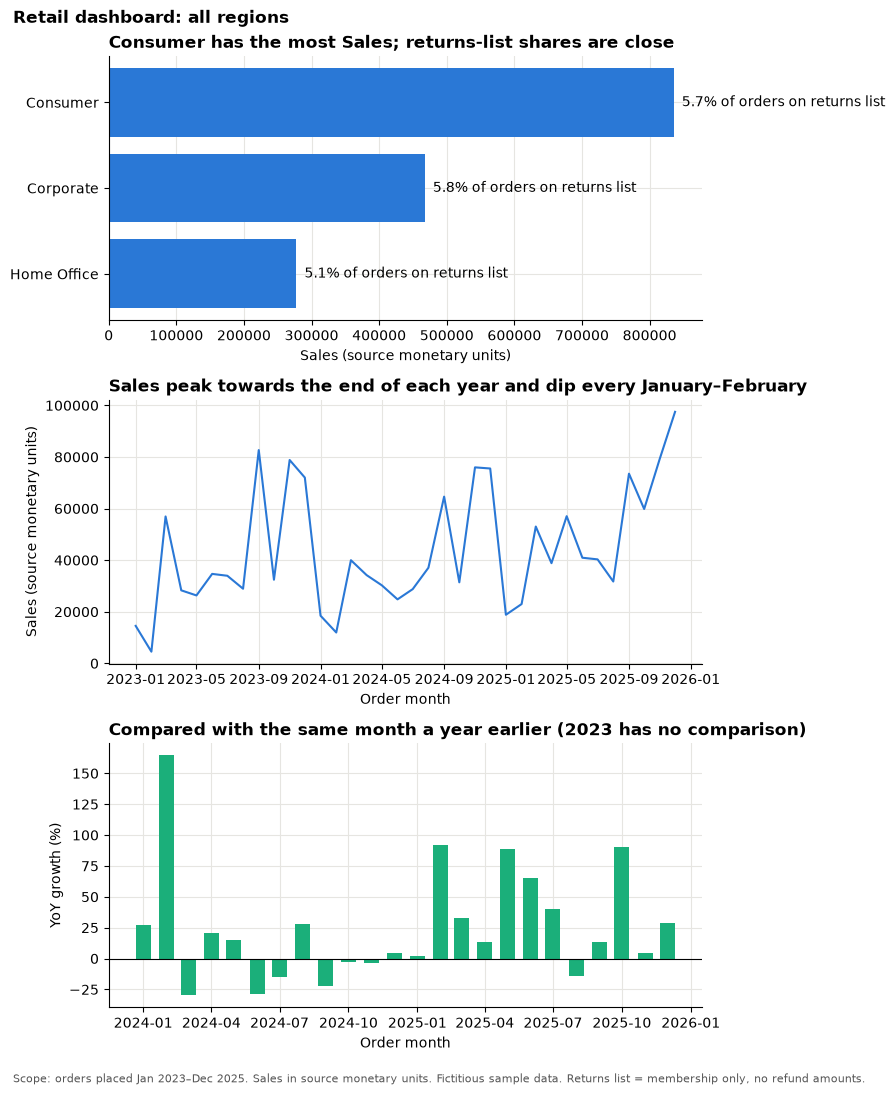

,sales,orders,listed,share_on_list_%
segment,,,,
Home Office,"277,656.95",606,31,5.10
Corporate,"467,562.02",1044,61,5.80
Consumer,"835,747.86",1738,99,5.70


In [15]:
def draw_dashboard(data, scope):
    # 1. Segment KPIs
    kpis = pd.DataFrame({
        "sales": data.groupby("segment")["sales"].sum(),
        "orders": data.groupby("segment")["order_id"].nunique(),
        "listed": data[data["returned_order_flag"] == 1].groupby("segment")["order_id"].nunique(),
    }).fillna(0).astype({"listed": int}).sort_values("sales")
    kpis["share_on_list"] = kpis["listed"] / kpis["orders"]

    # 2. Complete monthly series (0 where the selection has no lines)
    trend = data.groupby("order_month")["sales"].sum().reindex(all_months, fill_value=0)

    # 3. YoY growth on the full series; zero comparison month means no comparison
    yoy = trend.pct_change(periods=12).where(trend.shift(12) != 0)

    fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(9, 11))

    ax1.barh(kpis.index, kpis["sales"])
    for i, share in enumerate(kpis["share_on_list"]):
        ax1.text(kpis["sales"].iloc[i], i, f"  {share:.1%} of orders on returns list", va="center")
    ax1.set_title(f"{kpis.index[-1]} has the most Sales; returns-list shares are close")
    ax1.set_xlabel("Sales (source monetary units)")

    ax2.plot(trend.index, trend.values)
    ax2.set_title("Sales peak towards the end of each year and dip every January–February")
    ax2.set_xlabel("Order month")
    ax2.set_ylabel("Sales (source monetary units)")

    ax3.bar(yoy.index, yoy * 100, width=20, color="#1baf7a")
    ax3.axhline(0, color="black", linewidth=0.8)
    ax3.set_title("Compared with the same month a year earlier (2023 has no comparison)")
    ax3.set_xlabel("Order month")
    ax3.set_ylabel("YoY growth (%)")

    fig.suptitle(f"Retail dashboard: {scope}", fontweight="bold", x=0.02, ha="left")
    fig.text(0.02, 0.005, "Scope: orders placed Jan 2023–Dec 2025. Sales in source monetary units. "
             "Fictitious sample data. Returns list = membership only, no refund amounts.",
             fontsize=8, color="#555555")
    fig.tight_layout(rect=[0, 0.02, 1, 1])
    plt.show()
    kpis["share_on_list"] = (kpis["share_on_list"] * 100).round(1)
    return kpis.rename(columns={"share_on_list": "share_on_list_%"})


draw_dashboard(df, "all regions")

The table under the chart is the segment KPI table the function returned. The message titles were written after reading these charts on the full data; if you redraw for one region, check that each title is still true and change it if not.

### Design checks

Use what you learned in [Designing clear visuals](../foundations/visual-design.md):

- [ ] The most important view is at the top.
- [ ] Every chart has a title that states a message and labelled axes with units.
- [ ] Colour is used only where it means something.
- [ ] Nothing can be understood only by colour; labels or a table are available too.
- [ ] The scope note states the period, units and that the data is a fictitious sample.

---

## Part 6: Your turn

### 1. Redraw the dashboard for one region

> **Your turn:** change the code in the next cell and run it again.

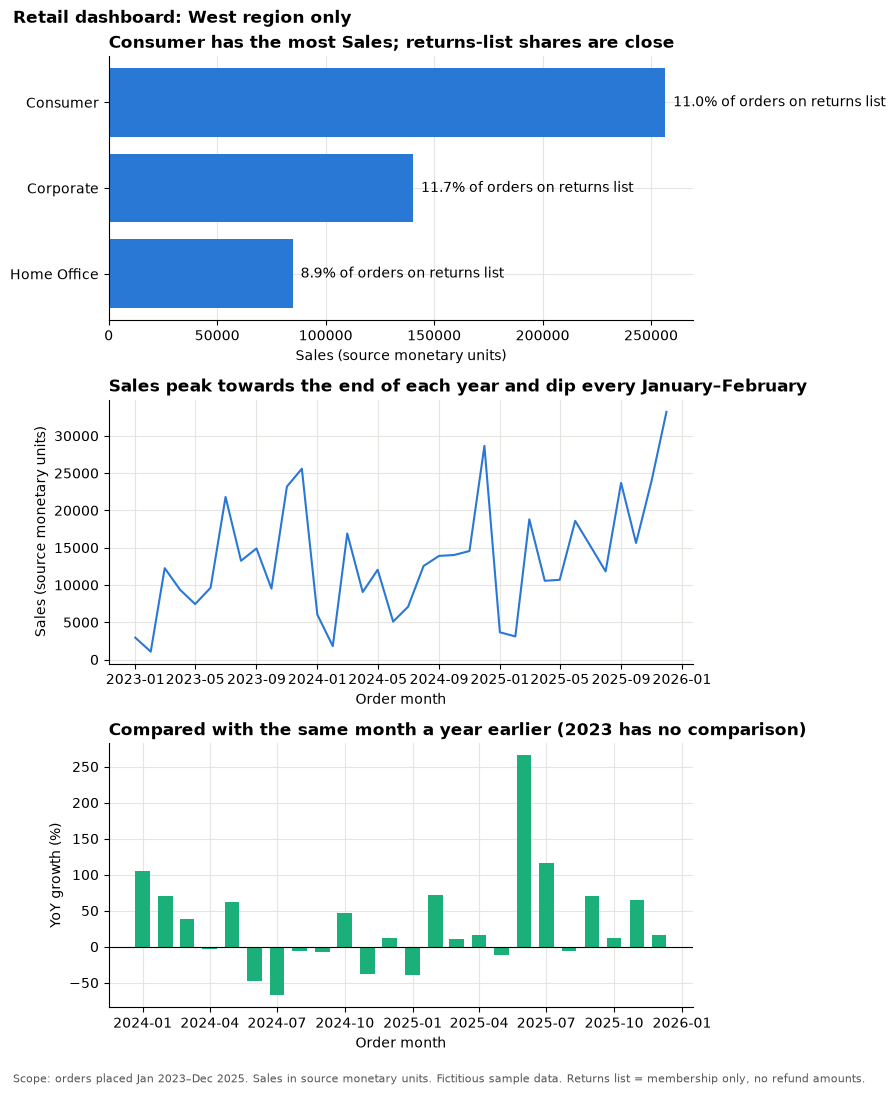

,sales,orders,listed,share_on_list_%
segment,,,,
Home Office,"84,769.73",203,18,8.90
Corporate,"140,280.49",324,38,11.70
Consumer,"256,522.36",562,62,11.00


In [16]:
# 1. Change "West" to another region: "East", "Central" or "South".
# 2. Run the cell. Read every title: is each message still true for this region?
# 3. If a title is no longer true, write down what it should say instead.
region = "West"
draw_dashboard(df[df["region"] == region], f"{region} region only")

### 2. One segment over three years

This code adds up Sales by quarter for one segment and puts the years side by side, so you compare the **same quarter** across years.

> **Your turn:** change the code in the next cell and run it again.

In [17]:
# 1. Change "Consumer" to "Corporate" or "Home Office".
# 2. For each quarter, is the segment growing, flat or falling across the years?
# 3. Describe the segment's trend in three sentences.
segment = "Consumer"
one_segment = df[df["segment"] == segment]
quarterly = one_segment.groupby([one_segment["order_date"].dt.quarter,
                                 one_segment["order_date"].dt.year])["sales"].sum().unstack()
quarterly.index.name = "quarter"
quarterly

order_date,2023,2024,2025
quarter,,,
1,"21,964.98","40,962.89","46,744.16"
2,"48,942.87","56,445.35","70,813.86"
3,"97,130.76","79,582.04","80,842.86"
4,"100,661.57","90,342.28","101,314.24"


### 3. Growth for one segment

Change the segment and the months. Remember: build the full series for the segment first, then pick the months to show.

> **Your turn:** change the code in the next cell and run it again.

In [18]:
# 1. Change "Consumer" to another segment.
# 2. Change the months in the list to two or three months you want to inspect.
# 3. Is the MoM or the YoY figure the fairer one to report for each month? Why?
segment = "Consumer"
seg = df[df["segment"] == segment].groupby("order_month")["sales"].sum().reindex(all_months, fill_value=0)
seg_growth = pd.DataFrame({"sales": seg})
seg_growth["mom_growth"] = seg.pct_change().where(seg.shift(1) != 0)
seg_growth["yoy_growth"] = seg.pct_change(periods=12).where(seg.shift(12) != 0)
growth_table(seg_growth, ["2024-12-01", "2025-01-01", "2025-06-01"])

,Sales,MoM growth,YoY growth
Dec 2024,"40,067",+20.9%,+5.9%
Jan 2025,"6,027",-85.0%,-57.8%
Jun 2025,"24,430",-24.2%,+90.5%


---

## Part 7: Debugging challenge

A colleague posts this in a team chat:

> *"Disaster! Sales fell about 75% in January 2025. And I filtered the dashboard to 2025 to check, but now January's growth is blank. Something is broken."*

First, reproduce the colleague's figure, then look at the comparison they did not make.

In [19]:
january = growth.loc["2025-01-01"]
print("January 2025 Sales:            ", f"{january['sales']:,.0f}")
print("December 2024 Sales:           ", f"{january['previous_month']:,.0f}")
print("Month-on-month growth:         ", as_pct(january["mom_growth"]))
print("January 2024 Sales:            ", f"{january['same_month_last_year']:,.0f}")
print("Year-on-year growth:           ", as_pct(january["yoy_growth"]))
print("MoM after filtering to 2025:   ", as_pct(filter_first.loc["2025-01-01", "mom_growth"]))

January 2025 Sales:             18,830
December 2024 Sales:            75,533
Month-on-month growth:          -75.1%
January 2024 Sales:             18,462
Year-on-year growth:            +2.0%
MoM after filtering to 2025:    no comparison


Use the output above, and the seasonal chart from Part 1, to answer:

1. Is January's fall a real problem or a seasonal pattern? Which growth measure would you show instead, and what does it say?
2. Why did January's month-on-month growth become blank after filtering to 2025?
3. Rewrite the colleague's message so it is accurate. Mention the comparison month you used.

> **Hint**
>
> Look at what happened every January in the seasonal chart, not just in 2025. Then go back to Part 3.

---

## Part 8: Recommend a test

Write **five sentences** to the commercial lead:

1. **The test:** one specific change to try, in one segment.
2. **Evidence:** one measure from the trend or growth views.
3. **Evidence:** one measure from the segment table, including the returns-list share.
4. **Limitation:** for example, the trend shows *when* sales change, not *why*; the returns list has no refund amounts; the data is a fictitious sample.
5. **How to measure success:** the measure and comparison you would use to judge the test, such as YoY Sales for the same months, or the same months in a similar group that did not get the change.

> **Why a test?**
>
> Past data shows patterns, not causes. A segment growing at the same time as something else happened is an **association**, not proof that one caused the other. A small, well-measured test, compared fairly with the same months last year or with an untouched group, is how you find out whether a change actually works.

---

## Validation checklist

- [ ] The monthly series has all 36 months, Jan 2023 to Dec 2025, with no gaps.
- [ ] Growth was computed on the complete series **before** filtering to a period.
- [ ] Blanks appear only where no comparison exists, and are never shown as 0%.
- [ ] Returns are counted as **distinct orders**, not lines, and called "share of orders on the returns list".
- [ ] Segment order counts add up to the all-segments total.
- [ ] Every chart has a message title, labelled axes with units, and the dashboard has a scope note.

---

## Exit ticket

1. Why can month-on-month growth mislead for a seasonal business?
2. Why does filtering to one year before computing growth create blanks?
3. What is one thing the returns list cannot tell you?
4. What would you measure to judge whether your proposed test worked?

## After the lesson

- Save your dashboard image (right-click the chart in Colab and save it) and your five-sentence recommendation. Together they form your **retail portfolio checkpoint**.
- Record in your evidence log: the data version, any filters you used and your growth and returns definitions.